<a href="https://colab.research.google.com/github/harshitadalne/AI-Practicals-Python-/blob/main/NNDL_Practical_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q tensorflow-datasets importlib-resources

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/tf_flowers/incomplete.3IEQBW_3.0.1/tf_flowers-train.tfrecord-[0-9][0-9][0-…

Dataset tf_flowers downloaded and prepared to /root/tensorflow_datasets/tf_flowers/3.0.1. Subsequent calls will reuse this data.
Classes: ['dandelion', 'daisy', 'tulips', 'sunflowers', 'roses']


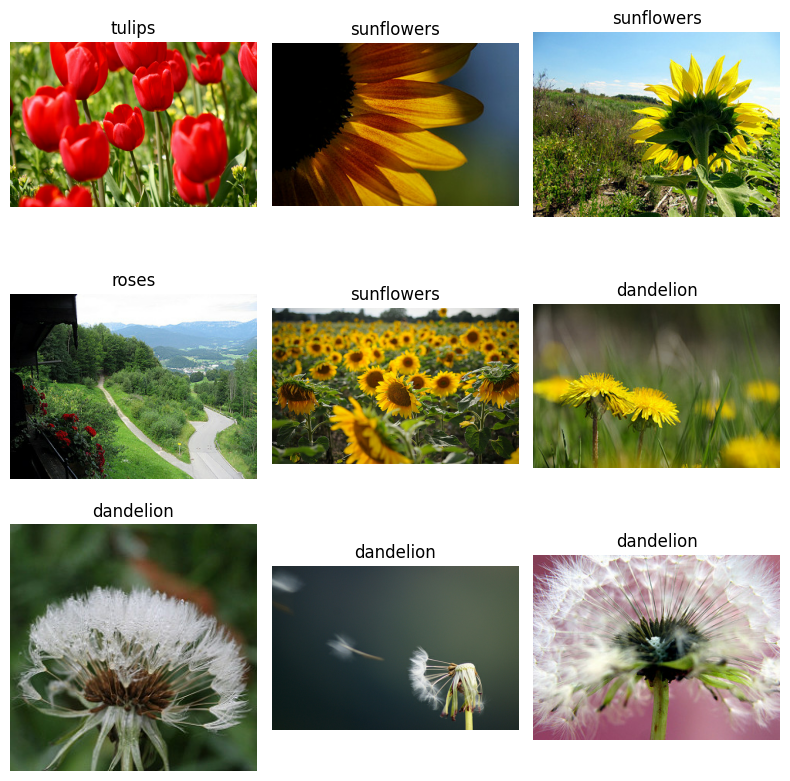

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,597 (9.24 MB)

 Trainable params: 164,613 (643.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 107s 1s/step - accuracy: 0.7691 - loss: 0.6411 - val_accuracy: 0.8542 - val_loss: 0.3769
Epoch 2/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 86s 932ms/step - accuracy: 0.8876 - loss: 0.3094 - val_accuracy: 0.8896 - val_loss: 0.3153
Epoch 3/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 81s 882ms/step - accuracy: 0.9176 - loss: 0.2287 - val_accuracy: 0.8733 - val_loss: 0.3341
Epoch 4/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 84s 910ms/step - accuracy: 0.9445 - loss: 0.1619 - val_accuracy: 0.8747 - val_loss: 0.3309
Epoch 5/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 78s 854ms/step - accuracy: 0.9584 - loss: 0.1269 - val_accuracy: 0.8896 - val_loss: 0.3219
23/23 ━━━━━━━━━━━━━━━━━━━━ 16s 690ms/step - accuracy: 0.8896 - loss: 0.3219
Validation Loss = 0.3219166696071625
Validation Accuracy = 0.8896457552909851
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
Predicted: roses
Actual: roses


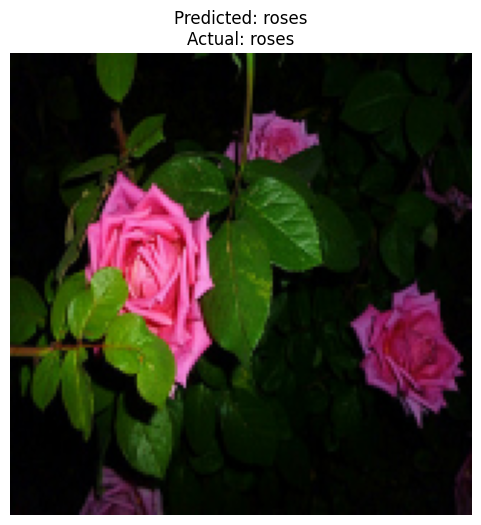

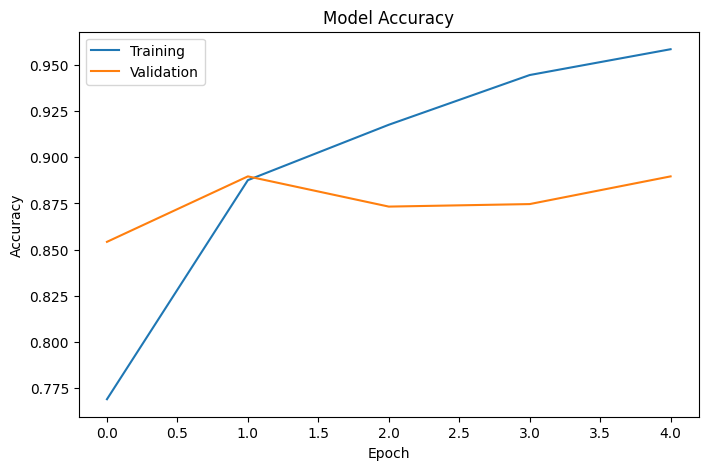

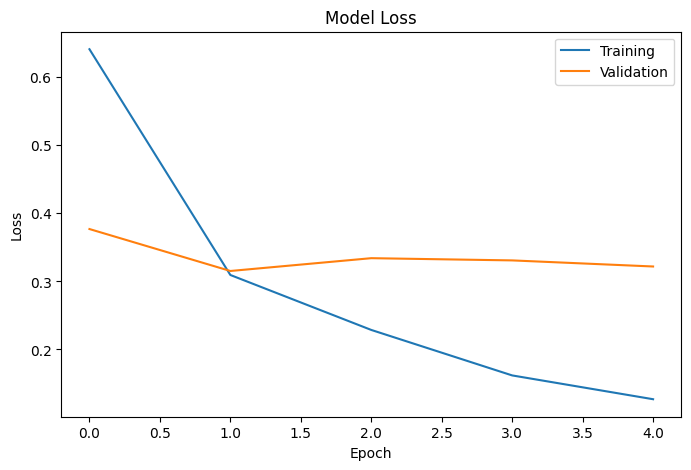

In [ ]:
import tensorflow as tf
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt
import numpy as np

from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.applications import MobileNetV2

(train_ds, validation_ds), dataset_info = tfds.load(
    "tf_flowers",
    split=["train[:80%]", "train[80%:]"],
    as_supervised=True,
    with_info=True
)

class_names = dataset_info.features["label"].names

print("Classes:", class_names)

plt.figure(figsize=(8, 8))

for i, (image, label) in enumerate(train_ds.take(9)):
    plt.subplot(3, 3, i + 1)
    plt.imshow(image)
    plt.title(class_names[label.numpy()])
    plt.axis("off")

plt.tight_layout()
plt.show()

IMG_SIZE = (160, 160)

train_ds = train_ds.map(
    lambda x, y: (tf.image.resize(x, IMG_SIZE) / 255.0, y)
)

validation_ds = validation_ds.map(
    lambda x, y: (tf.image.resize(x, IMG_SIZE) / 255.0, y)
)

train_ds = train_ds.batch(32).prefetch(tf.data.AUTOTUNE)
validation_ds = validation_ds.batch(32).prefetch(tf.data.AUTOTUNE)

base_model = MobileNetV2(
    input_shape=(160, 160, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

model = Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(5, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

history = model.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=5
)

loss, accuracy = model.evaluate(validation_ds)

print("Validation Loss =", loss)
print("Validation Accuracy =", accuracy)

for images, labels in validation_ds.take(1):
    prediction = model.predict(images)

predicted = np.argmax(prediction[0])
actual = labels[0].numpy()

print("Predicted:", class_names[predicted])
print("Actual:", class_names[actual])

plt.figure(figsize=(6, 6))

plt.imshow(images[0])
plt.title(
    f"Predicted: {class_names[predicted]}\n"
    f"Actual: {class_names[actual]}"
)
plt.axis("off")
plt.show()

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation"
)

plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training"
)

plt.plot(
    history.history["val_loss"],
    label="Validation"
)

plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()